In [1]:
#Loading of CSV files

import pandas as pd
import numpy as np

customers = pd.read_csv('Dataset/customers.csv')
order_items = pd.read_csv('Dataset/order_items.csv')
orders = pd.read_csv('Dataset/orders.csv')
products = pd.read_csv('Dataset/products.csv')

In [2]:
#Creating copies of data

customers_clean = customers.copy()
products_clean = products.copy()
orders_clean = orders.copy()
order_items_clean = order_items.copy()

In [3]:
#Inspection of data for customers_clean

customers_clean.info()

<class 'pandas.DataFrame'>
RangeIndex: 5050 entries, 0 to 5049
Data columns (total 13 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   customer_id   5050 non-null   str    
 1   first_name    5050 non-null   str    
 2   last_name     5050 non-null   str    
 3   gender        4749 non-null   str    
 4   age           4900 non-null   float64
 5   email         4943 non-null   str    
 6   phone         4903 non-null   float64
 7   region_code   5050 non-null   str    
 8   region_name   5050 non-null   str    
 9   city          5050 non-null   str    
 10  barangay      5050 non-null   str    
 11  signup_date   5050 non-null   str    
 12  loyalty_tier  4784 non-null   str    
dtypes: float64(2), str(11)
memory usage: 997.1 KB


In [4]:
#Checking of missing values for customers_clean

print(customers_clean.isnull().sum())

customer_id       0
first_name        0
last_name         0
gender          301
age             150
email           107
phone           147
region_code       0
region_name       0
city              0
barangay          0
signup_date       0
loyalty_tier    266
dtype: int64


In [5]:
#Checking of duplicated records for customers_clean

print("customers_clean duplicates:",customers_clean.duplicated().sum())

customers_clean duplicates: 50


In [6]:
#Removing exact duplicates while generating new copies of data

customers_clean = customers_clean.drop_duplicates().copy()

In [7]:
#Removing leading and trailing spaces from all text columns

text_columns = customers_clean.select_dtypes(include='object').columns

for column in text_columns:
    customers_clean[column] = customers_clean[column].str.strip()

#Does it work?
customers_clean['gender'].value_counts()

C:\Users\Ian Yes Dalawampu\AppData\Local\Temp\ipykernel_15744\2001035142.py:3: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  text_columns = customers_clean.select_dtypes(include='object').columns


gender
M          1297
F          1263
Female      721
Male        719
Unknown     587
female      115
Name: count, dtype: int64

In [8]:
#Standardize gender values

customers_clean['gender'] = customers_clean['gender'].replace({
    'M': 'Male',
    'F': 'Female',
    'female': 'Female'
})

#Does it work?
customers_clean['gender'].value_counts()

gender
Female     2099
Male       2016
Unknown     587
Name: count, dtype: int64

In [9]:
#Standardize names and locations

customers_clean['first_name'] = customers_clean['first_name'].str.title()
customers_clean['last_name'] = customers_clean['last_name'].str.title()

customers_clean['city'] = customers_clean['city'].str.title()
customers_clean['barangay'] = customers_clean['barangay'].str.title()

#Does it work?
customers_clean['city'].value_counts().head()

city
Olongapo          305
San Fernando      289
Iligan            279
Cagayan De Oro    272
Angeles           263
Name: count, dtype: int64

In [10]:
#Standardize email addresses

customers_clean['email'] = customers_clean['email'].str.lower()

#Does it work?
customers_clean['email'].value_counts().head()

email
grace.castillo@yahoo.com        8
nina.gonzales@companymail.ph    7
juan.mendoza@gmail.com          6
ella.delosreyes@mail.com        6
maria.lopez@mail.com            6
Name: count, dtype: int64

In [11]:
#Standardize loyalty tiers

customers_clean['loyalty_tier'] = customers_clean['loyalty_tier'].str.title()

#Does it work?
customers_clean['loyalty_tier'].value_counts()

loyalty_tier
Bronze      2204
Silver      1257
Gold         915
Platinum     360
Name: count, dtype: int64

In [12]:
#Standardize region_name

customers_clean['region_name'] = customers_clean['region_name'].replace({
    'Calabarzon': 'CALABARZON',
    'Caraga': 'CARAGA'
})

#Does it work?
customers_clean['region_name'].value_counts()

region_name
Central Luzon        857
Metro Manila         848
Central Visayas      842
CALABARZON           834
CARAGA               812
Northern Mindanao    807
Name: count, dtype: int64

In [13]:
#Check data

customers_clean.head()

,customer_id,first_name,last_name,gender,age,email,phone,region_code,region_name,city,barangay,signup_date,loyalty_tier
0,CUST000001,Grace,Delosreyes,NaN,20.0,grace.delosreyes95@outlook.com,9.196001e+09,Region III,Central Luzon,Angeles,Brgy 1,2025-12-31,Bronze
1,CUST000002,Ana,Ramos,Female,35.0,ana.ramos@companymail.ph,9.026542e+09,CARAGA,CARAGA,Butuan,Brgy 9,2025-02-08,Bronze
2,CUST000003,Arvin,Navarro,Male,14.0,arvin.navarrooutlook.com,9.161850e+09,NCR,Metro Manila,Pasig,Brgy 2,2023-09-10,Bronze
3,CUST000004,Kyle,Rivera,Female,26.0,kyle.rivera13@outlook.com,9.752553e+09,Region III,Central Luzon,Angeles,Brgy 1,2024-11-17,NaN
4,CUST000005,Juan,Mendoza,Male,29.0,juan.mendoza@gmail.com,9.350306e+09,Region III,Central Luzon,Angeles,Brgy 9,2023-01-21,Gold


In [14]:
#Check invalid ages

customers_clean[customers_clean['age'] < 0]

,customer_id,first_name,last_name,gender,age,email,phone,region_code,region_name,city,barangay,signup_date,loyalty_tier
162,CUST000163,Ana,Delosreyes,Female,-1.0,ana.delosreyes@gmail.com,9.876768e+09,Region VII,Central Visayas,Tagbilaran,Brgy 10,2024-12-31,Silver
329,CUST000330,Arvin,Rivera,Male,-1.0,arvin.rivera2@companymail.ph,9.780973e+09,Region VII,Central Visayas,Lapu-Lapu,Brgy 2,02-Jul-2025,Bronze
696,CUST000697,Kyle,Ramos,Female,-1.0,kyle.ramos@yahoo.com,9.206497e+09,Region III,Central Luzon,Angeles,Brgy 9,05/23/2025,Gold
718,CUST000719,Ramon,Garcia,Unknown,-1.0,ramon.garcia@outlook.com,9.480940e+09,Region IV-A,CALABARZON,Cavite City,Brgy 4,2025-04-27,Gold
872,CUST000873,Mark,Pascual,Male,-1.0,markpascual@yahoocom,9.040477e+08,CARAGA,CARAGA,Tandag,Brgy 4,2023-03-06,Silver
1194,CUST001195,Kyle,Bautista,Unknown,-1.0,kyle.bautista@yahoo.com,9.448676e+09,Region III,Central Luzon,San Fernando,Brgy 5,2025-11-24,Bronze
1220,CUST001221,Ramon,Diaz,Male,-1.0,ramon.diaz@gmail.com,9.444705e+09,Region III,Central Luzon,San Fernando,Brgy 4,21-Jul-2025,Silver
1227,CUST001228,James,Fernandez,Male,-1.0,james.fernandez@mail.com,9.488064e+09,Region X,Northern Mindanao,Valencia,Brgy 8,19-Mar-2023,Bronze
1303,CUST001304,Faith,Santos,Female,-1.0,faith.santos@gmail.com,9.232738e+09,CARAGA,CARAGA,Butuan,Brgy 2,2024-07-01,Gold
1425,CUST001426,Nina,Navarro,Male,-1.0,nina.navarro@yahoo.com,9.447082e+09,NCR,Metro Manila,Makati,Brgy 4,2024-06-08,Bronze


In [15]:
#Check ages = 0

customers_clean[customers_clean['age'] == 0]

,customer_id,first_name,last_name,gender,age,email,phone,region_code,region_name,city,barangay,signup_date,loyalty_tier
4547,CUST004548,Liza,Garcia,Female,0.0,liza.garciaoutlook.com,9.381006e+09,NCR,Metro Manila,Pasig,Brgy 2,2024-01-20,NaN


In [16]:
#Check ages with null values

customers_clean[customers_clean['age'].isnull()]

,customer_id,first_name,last_name,gender,age,email,phone,region_code,region_name,city,barangay,signup_date,loyalty_tier
26,CUST000027,Kyle,Lopez,Unknown,NaN,kyle.lopez75@companymail.ph,9.577739e+09,CARAGA,CARAGA,Tandag,Brgy 7,2023-06-01,Platinum
40,CUST000041,Ramon,Navarro,Male,NaN,ramon.navarro32@outlook.com,9.957886e+09,Region IV-A,CALABARZON,Batangas City,Brgy 8,2025-02-12,Bronze
48,CUST000049,Arvin,Santos,Female,NaN,arvin.santos@gmail.com,9.049028e+09,NCR,Metro Manila,Pasig,Brgy 6,2025-12-02,Bronze
94,CUST000095,Arvin,Flores,Female,NaN,arvin.flores@yahoo.com,9.095396e+09,NCR,Metro Manila,Quezon City,Brgy 8,2023-01-10,Silver
124,CUST000125,Jasmine,Reyes,Unknown,NaN,jasmine.reyes@outlook.com,9.296685e+09,Region III,Central Luzon,San Fernando,Brgy 5,2025-05-03,Silver
...,...,...,...,...,...,...,...,...,...,...,...,...,...
4894,CUST004895,Nina,Navarro,Male,NaN,ninanavarro@companymailph,9.755676e+09,Region III,Central Luzon,Olongapo,Brgy 4,2024-06-21,Silver
4908,CUST004909,Liza,Navarro,Female,NaN,liza.navarro99@companymail.ph,9.951420e+09,NCR,Metro Manila,Taguig,Brgy 2,2025-04-10,Bronze
4934,CUST004935,Arvin,Bautista,Male,NaN,arvin.bautista@mail.com,9.855038e+08,NCR,Metro Manila,Manila,Brgy 4,2025-01-14,Silver
4944,CUST004945,Maria,Pascual,Unknown,NaN,maria.pascual@yahoo.com,9.357814e+09,Region III,Central Luzon,San Fernando,Brgy 10,23-Feb-2024,Bronze


In [17]:
#Replace negative and zero ages with NaN (make sure to import numpy as np)

customers_clean.loc[customers_clean['age'] <= 0, 'age'] = np.nan

#Does it work?

print("Missing ages:", customers_clean['age'].isnull().sum())
print("Negative ages:", (customers_clean['age'] < 0).sum())
print("Zero ages:", (customers_clean['age'] == 0).sum())

Missing ages: 198
Negative ages: 0
Zero ages: 0


In [18]:
#Fill gender with null values with 'Unknown'

customers_clean['gender'] = customers_clean['gender'].fillna('Unknown')

#Does it work?
customers_clean['gender'].value_counts()

gender
Female     2099
Male       2016
Unknown     885
Name: count, dtype: int64

In [19]:
#Fill loyalty tiers with null values with 'Not Assigned'

customers_clean['loyalty_tier'] = customers_clean['loyalty_tier'].fillna('Not Assigned')

#Does it work?

customers_clean['loyalty_tier'].value_counts()

loyalty_tier
Bronze          2204
Silver          1257
Gold             915
Platinum         360
Not Assigned     264
Name: count, dtype: int64

In [20]:
#Check the cleaned data

customers_clean.isnull().sum()

customer_id       0
first_name        0
last_name         0
gender            0
age             198
email           104
phone           145
region_code       0
region_name       0
city              0
barangay          0
signup_date       0
loyalty_tier      0
dtype: int64

In [21]:
#Convert phone numbers to string

customers_clean['phone'] = customers_clean['phone'].astype('string')

#Does it work?

customers_clean[['customer_id', 'phone']].head()

,customer_id,phone
0,CUST000001,9196001338.0
1,CUST000002,9026542351.0
2,CUST000003,9161849593.0
3,CUST000004,9752553419.0
4,CUST000005,9350305641.0


In [22]:
#Check format of signup date

customers_clean['signup_date'].head(10)

0    2025-12-31
1    2025-02-08
2    2023-09-10
3    2024-11-17
4    2023-01-21
5    2025-08-13
6    2025-10-22
7    2025-09-22
8    2025-12-12
9    2024-06-04
Name: signup_date, dtype: str

In [23]:
#Check signup date data type
customers_clean['signup_date'].dtype

<StringDtype(na_value=nan)>

In [24]:
#Conver to datetime

customers_clean['signup_date'] = pd.to_datetime(
    customers_clean['signup_date'],
    errors = 'coerce'
)

#Does it work?

customers_clean['signup_date'].dtype

dtype('<M8[us]')

In [25]:
#Check the signup_date

customers_clean[['customer_id', 'signup_date']].head(10)

,customer_id,signup_date
0,CUST000001,2025-12-31
1,CUST000002,2025-02-08
2,CUST000003,2023-09-10
3,CUST000004,2024-11-17
4,CUST000005,2023-01-21
5,CUST000006,2025-08-13
6,CUST000007,2025-10-22
7,CUST000008,2025-09-22
8,CUST000009,2025-12-12
9,CUST000010,2024-06-04


In [26]:
#Check for missing and invalid dates

customers_clean[customers_clean['signup_date'].isna()]

,customer_id,first_name,last_name,gender,age,email,phone,region_code,region_name,city,barangay,signup_date,loyalty_tier
12,CUST000013,Paolo,Cruz,Female,22.0,paolo.cruz@outlook.com,9010651333.0,Region X,Northern Mindanao,Cagayan De Oro,Brgy 8,NaT,Gold
14,CUST000015,Jose,Torres,Female,23.0,NaN,9746872343.0,Region X,Northern Mindanao,Iligan,Brgy 4,NaT,Silver
18,CUST000019,Juan,Aquino,Male,33.0,juan.aquino@yahoo.com,9124118244.0,Region III,Central Luzon,San Fernando,Brgy 10,NaT,Bronze
27,CUST000028,Ana,Flores,Female,29.0,ana.flores@outlook.com,9037917693.0,Region VII,Central Visayas,Mandaue,Brgy 2,NaT,Platinum
29,CUST000030,Arvin,Diaz,Female,31.0,arvin.diaz97@gmail.com,9986872774.0,NCR,Metro Manila,Pasig,Brgy 3,NaT,Bronze
...,...,...,...,...,...,...,...,...,...,...,...,...,...
4981,CUST004982,Juan,Delosreyes,Female,47.0,juan.delosreyes@yahoo.com,9576913647.0,NCR,Metro Manila,Quezon City,Brgy 2,NaT,Bronze
4987,CUST004988,Grace,Delosreyes,Female,19.0,grace.delosreyes@outlook.com,9202279617.0,Region VII,Central Visayas,Mandaue,Brgy 10,NaT,Gold
4993,CUST004994,Noah,Pascual,Unknown,36.0,noah.pascual@gmail.com,9139211808.0,Region IV-A,CALABARZON,Calamba,Brgy 6,NaT,Bronze
4996,CUST004997,Mia,Flores,Male,55.0,miaflores@outlookcom,9050211925.0,Region III,Central Luzon,Olongapo,Brgy 10,NaT,Bronze


In [27]:
#Check region_code

customers_clean['region_code'].value_counts()

region_code
Region III     857
NCR            848
Region VII     842
Region IV-A    834
CARAGA         812
Region X       807
Name: count, dtype: int64

In [28]:
#Check overall customers data

customers_clean.info()

<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 13 columns):
 #   Column        Non-Null Count  Dtype         
---  ------        --------------  -----         
 0   customer_id   5000 non-null   str           
 1   first_name    5000 non-null   str           
 2   last_name     5000 non-null   str           
 3   gender        5000 non-null   str           
 4   age           4802 non-null   float64       
 5   email         4896 non-null   str           
 6   phone         4855 non-null   string        
 7   region_code   5000 non-null   str           
 8   region_name   5000 non-null   str           
 9   city          5000 non-null   str           
 10  barangay      5000 non-null   str           
 11  signup_date   3719 non-null   datetime64[us]
 12  loyalty_tier  5000 non-null   str           
dtypes: datetime64[us](1), float64(1), str(10), string(1)
memory usage: 1012.7 KB


In [29]:
#Convert age to 'Int64' data type

customers_clean['age'] = customers_clean['age'].astype('Int64')

#Does it work?

customers_clean.info()

<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 13 columns):
 #   Column        Non-Null Count  Dtype         
---  ------        --------------  -----         
 0   customer_id   5000 non-null   str           
 1   first_name    5000 non-null   str           
 2   last_name     5000 non-null   str           
 3   gender        5000 non-null   str           
 4   age           4802 non-null   Int64         
 5   email         4896 non-null   str           
 6   phone         4855 non-null   string        
 7   region_code   5000 non-null   str           
 8   region_name   5000 non-null   str           
 9   city          5000 non-null   str           
 10  barangay      5000 non-null   str           
 11  signup_date   3719 non-null   datetime64[us]
 12  loyalty_tier  5000 non-null   str           
dtypes: Int64(1), datetime64[us](1), str(10), string(1)
memory usage: 1017.5 KB


In [30]:
customers_clean.head(10)

,customer_id,first_name,last_name,gender,age,email,phone,region_code,region_name,city,barangay,signup_date,loyalty_tier
0,CUST000001,Grace,Delosreyes,Unknown,20,grace.delosreyes95@outlook.com,9196001338.0,Region III,Central Luzon,Angeles,Brgy 1,2025-12-31,Bronze
1,CUST000002,Ana,Ramos,Female,35,ana.ramos@companymail.ph,9026542351.0,CARAGA,CARAGA,Butuan,Brgy 9,2025-02-08,Bronze
2,CUST000003,Arvin,Navarro,Male,14,arvin.navarrooutlook.com,9161849593.0,NCR,Metro Manila,Pasig,Brgy 2,2023-09-10,Bronze
3,CUST000004,Kyle,Rivera,Female,26,kyle.rivera13@outlook.com,9752553419.0,Region III,Central Luzon,Angeles,Brgy 1,2024-11-17,Not Assigned
4,CUST000005,Juan,Mendoza,Male,29,juan.mendoza@gmail.com,9350305641.0,Region III,Central Luzon,Angeles,Brgy 9,2023-01-21,Gold
5,CUST000006,Jasmine,Reyes,Female,31,jasmine.reyes@companymail.ph,9388496965.0,Region IV-A,CALABARZON,San Pablo,Brgy 6,2025-08-13,Gold
6,CUST000007,Juan,Diaz,Female,18,juan.diaz@companymail.ph,9691669784.0,Region IV-A,CALABARZON,Dasmariñas,Brgy 9,2025-10-22,Bronze
7,CUST000008,Leo,Navarro,Unknown,28,leo.navarro@companymail.ph,9270482814.0,CARAGA,CARAGA,Butuan,Brgy 2,2025-09-22,Not Assigned
8,CUST000009,Kyle,Castillo,Female,36,kyle.castillo@companymail.ph,9957015430.0,Region III,Central Luzon,Olongapo,Brgy 10,2025-12-12,Bronze
9,CUST000010,Mia,Castillo,Male,32,mia.castillo99@gmail.com,9782489638.0,Region IV-A,CALABARZON,San Pablo,Brgy 2,2024-06-04,Gold


In [31]:
#Inspection of data for orders_clean

orders_clean.info()

<class 'pandas.DataFrame'>
RangeIndex: 15075 entries, 0 to 15074
Data columns (total 8 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   order_id         15075 non-null  str    
 1   customer_id      15075 non-null  str    
 2   order_datetime   15075 non-null  str    
 3   order_status     15075 non-null  str    
 4   sales_channel    15075 non-null  str    
 5   shipping_method  15075 non-null  str    
 6   discount_pct     14317 non-null  float64
 7   shipping_fee     14601 non-null  float64
dtypes: float64(2), str(6)
memory usage: 1.8 MB


In [32]:
#Checking of missing values for orders_clean

print(orders_clean.isnull().sum())

order_id             0
customer_id          0
order_datetime       0
order_status         0
sales_channel        0
shipping_method      0
discount_pct       758
shipping_fee       474
dtype: int64


In [33]:
#Checking of duplicated records for orders_clean

print("orders_clean duplicates:",orders_clean.duplicated().sum())

orders_clean duplicates: 75


In [34]:
#Removing exact duplicates while generating new copies of data

orders_clean = orders_clean.drop_duplicates().copy()

In [35]:
#Removing leading and trailing spaces from all text columns

orders_columns = orders_clean.select_dtypes(include='object').columns

for column in orders_columns:
    orders_clean[column] = orders_clean[column].str.strip()

#Does it work?
orders_clean['sales_channel'].value_counts()

C:\Users\Ian Yes Dalawampu\AppData\Local\Temp\ipykernel_15744\1482905829.py:3: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  orders_columns = orders_clean.select_dtypes(include='object').columns


sales_channel
Marketplace    5047
Mobile App     4985
Web            4968
Name: count, dtype: int64

In [36]:
#Fill discount_pct with null values with '0'

orders_clean['discount_pct'] = orders_clean['discount_pct'].fillna(0)

#Does it work?
orders_clean['discount_pct'].isnull().sum()

np.int64(0)

In [37]:
#Fill shipping_fee with null values with '0'

orders_clean['shipping_fee'] = orders_clean['shipping_fee'].fillna(0)

#Does it work?
orders_clean['shipping_fee'].isnull().sum()

np.int64(0)

In [38]:
#Check the cleaned data

orders_clean.isnull().sum()

order_id           0
customer_id        0
order_datetime     0
order_status       0
sales_channel      0
shipping_method    0
discount_pct       0
shipping_fee       0
dtype: int64

In [39]:
#Getting back original data of discount_pct and shipping_fee

orders_clean['discount_pct'] = orders['discount_pct']

orders_clean['shipping_fee'] = orders['shipping_fee']

#Does it work?

orders_clean.info()

<class 'pandas.DataFrame'>
RangeIndex: 15000 entries, 0 to 14999
Data columns (total 8 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   order_id         15000 non-null  str    
 1   customer_id      15000 non-null  str    
 2   order_datetime   15000 non-null  str    
 3   order_status     15000 non-null  str    
 4   sales_channel    15000 non-null  str    
 5   shipping_method  15000 non-null  str    
 6   discount_pct     14244 non-null  float64
 7   shipping_fee     14530 non-null  float64
dtypes: float64(2), str(6)
memory usage: 1.8 MB


In [40]:
#Convert to datetime

orders_clean['order_datetime'] = pd.to_datetime(
    orders_clean['order_datetime'],
    errors = 'coerce'
)

#Does it work?

orders_clean.info()

<class 'pandas.DataFrame'>
RangeIndex: 15000 entries, 0 to 14999
Data columns (total 8 columns):
 #   Column           Non-Null Count  Dtype         
---  ------           --------------  -----         
 0   order_id         15000 non-null  str           
 1   customer_id      15000 non-null  str           
 2   order_datetime   11688 non-null  datetime64[us]
 3   order_status     15000 non-null  str           
 4   sales_channel    15000 non-null  str           
 5   shipping_method  15000 non-null  str           
 6   discount_pct     14244 non-null  float64       
 7   shipping_fee     14530 non-null  float64       
dtypes: datetime64[us](1), float64(2), str(5)
memory usage: 1.5 MB


In [41]:
#Check the overall cleaned data

orders_clean.head(10)

,order_id,customer_id,order_datetime,order_status,sales_channel,shipping_method,discount_pct,shipping_fee
0,ORD0000001,CUST000839,2025-11-07 17:02:00,Cancelled,Marketplace,Standard,0.074,102.68
1,ORD0000002,CUST002871,NaT,Completed,Marketplace,Express,0.063,0.00
2,ORD0000003,CUST000720,2025-08-08 04:59:00,Completed,Web,Standard,0.137,103.83
3,ORD0000004,CUST002515,2025-10-14 12:56:00,Completed,Web,Pickup,0.005,112.69
4,ORD0000005,CUST001544,2024-05-30 04:56:00,Completed,Marketplace,Pickup,NaN,111.73
5,ORD0000006,CUST001560,2024-08-13 18:42:00,Shipped,Mobile App,Pickup,0.089,86.54
6,ORD0000007,CUST001604,2025-08-11 23:17:00,Completed,Mobile App,Pickup,0.000,48.92
7,ORD0000008,CUST003022,NaT,Completed,Marketplace,Standard,0.164,82.75
8,ORD0000009,CUST000119,2024-09-28 02:01:00,Completed,Mobile App,Express,0.160,24.84
9,ORD0000010,CUST002982,2024-09-17 05:31:00,Shipped,Web,Pickup,0.102,80.61


In [42]:
#Inspection of data for order_items_clean

order_items_clean.info()

<class 'pandas.DataFrame'>
RangeIndex: 37763 entries, 0 to 37762
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype
---  ------                  --------------  -----
 0   order_item_id           37763 non-null  str  
 1   order_id                37763 non-null  str  
 2   product_id              37763 non-null  str  
 3   quantity                37763 non-null  int64
 4   unit_price_at_purchase  35501 non-null  str  
dtypes: int64(1), str(4)
memory usage: 2.8 MB


In [43]:
#Checking of null values in oredr_items_clean

order_items_clean.isnull().sum()

order_item_id                0
order_id                     0
product_id                   0
quantity                     0
unit_price_at_purchase    2262
dtype: int64

In [44]:
#Remove the peso symbol and commas

order_items_clean['unit_price_at_purchase'] = (
    order_items_clean['unit_price_at_purchase']
    .astype('string')
    .str.replace('₱','', regex = False)
    .str.replace(',', '', regex = False)
    .str.strip()
)

In [45]:
#Converting unit_price_at_purchase to numeric

order_items_clean['unit_price_at_purchase'] = pd.to_numeric(
    order_items_clean['unit_price_at_purchase'],
    errors = 'coerce'
)

In [46]:
#Check data types of order_items_clean

order_items_clean.info()

<class 'pandas.DataFrame'>
RangeIndex: 37763 entries, 0 to 37762
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   order_item_id           37763 non-null  str    
 1   order_id                37763 non-null  str    
 2   product_id              37763 non-null  str    
 3   quantity                37763 non-null  int64  
 4   unit_price_at_purchase  35501 non-null  Float64
dtypes: Float64(1), int64(1), str(3)
memory usage: 2.6 MB


In [47]:
order_items_clean

,order_item_id,order_id,product_id,quantity,unit_price_at_purchase
0,ITEM000000001,ORD0000001,PROD00513,2,120.67
1,ITEM000000002,ORD0000002,PROD00124,2,83.58
2,ITEM000000003,ORD0000002,PROD00631,2,46.96
3,ITEM000000004,ORD0000002,PROD00136,1,100.59
4,ITEM000000005,ORD0000002,PROD00090,1,109.18
...,...,...,...,...,...
37758,ITEM000037216,ORD0014888,PROD00095,3,48.27
37759,ITEM000028576,ORD0011406,PROD00702,1,46.31
37760,ITEM000026308,ORD0010493,PROD00358,1,130.84
37761,ITEM000020512,ORD0008174,PROD00075,3,42.93


In [48]:
#Inspection of data for products_clean

products_clean.info()

<class 'pandas.DataFrame'>
RangeIndex: 800 entries, 0 to 799
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   product_id    800 non-null    str    
 1   product_name  800 non-null    str    
 2   brand         800 non-null    str    
 3   category      800 non-null    str    
 4   unit_cost     800 non-null    float64
 5   unit_price    800 non-null    str    
 6   stock_qty     781 non-null    float64
 7   uom           800 non-null    str    
 8   launch_date   800 non-null    str    
dtypes: float64(2), str(7)
memory usage: 104.8 KB


In [49]:
#Standardize category

products_clean['category'].value_counts()

category
Beauty              94
Toys                92
Books               90
Fashion             89
Groceries           77
Home & Kitchen      76
Sports              74
Electronics         71
electronics         20
Book                20
Home and Kitchen    19
Electronics         17
Grocery             12
Elec                11
Beauty & Care       11
Toy                 11
Fashon               8
Sports & Outdoor     8
Name: count, dtype: int64

In [50]:
#Removing leading and trailing spaces from all text columns

products_columns = products_clean.select_dtypes(include='object').columns

for column in products_columns:
    products_clean[column] = products_clean[column].str.strip()

C:\Users\Ian Yes Dalawampu\AppData\Local\Temp\ipykernel_15744\1212291416.py:3: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  products_columns = products_clean.select_dtypes(include='object').columns


In [51]:
#Standardize categories

products_clean['category'] = products_clean['category'].str.title()

#Does it work?

products_clean['category'].value_counts()

category
Electronics         108
Beauty               94
Toys                 92
Books                90
Fashion              89
Groceries            77
Home & Kitchen       76
Sports               74
Book                 20
Home And Kitchen     19
Grocery              12
Elec                 11
Beauty & Care        11
Toy                  11
Fashon                8
Sports & Outdoor      8
Name: count, dtype: int64

In [52]:
#Standardize values of categories

products_clean['category'] = products_clean['category'].replace({
    'Elec': 'Electronics',
    'Beauty & Care': 'Beauty',
    'Toy': 'Toys',
    'Book': 'Books',
    'Fashon': 'Fashion',
    'Sports & Outdoor': 'Sports',
    'Home And Kitchen': 'Home & Kitchen',
    'Grocery': 'Groceries'
})

#Does it work?

products_clean['category'].value_counts()

category
Electronics       119
Books             110
Beauty            105
Toys              103
Fashion            97
Home & Kitchen     95
Groceries          89
Sports             82
Name: count, dtype: int64

In [53]:
#Remove the peso symbol and commas for unit_price

products_clean['unit_price'] = (
    products_clean['unit_price']
    .astype('string')
    .str.replace('₱','', regex = False)
    .str.replace(',', '', regex = False)
    .str.strip()
)

In [54]:
#Converting unit_price to numeric

products_clean['unit_price'] = pd.to_numeric(
    products_clean['unit_price'],
    errors = 'coerce'
)

#Does it work?

products_clean.info()

<class 'pandas.DataFrame'>
RangeIndex: 800 entries, 0 to 799
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   product_id    800 non-null    str    
 1   product_name  800 non-null    str    
 2   brand         800 non-null    str    
 3   category      800 non-null    str    
 4   unit_cost     800 non-null    float64
 5   unit_price    800 non-null    Float64
 6   stock_qty     781 non-null    float64
 7   uom           800 non-null    str    
 8   launch_date   800 non-null    str    
dtypes: Float64(1), float64(2), str(6)
memory usage: 101.7 KB


In [55]:
#Check values of uom

products_clean['uom'].value_counts()

uom
pcs       156
piece     140
pc        133
pack      125
bottle    123
set       123
Name: count, dtype: int64

In [56]:
#Standardize values of uom

products_clean['uom'] = products_clean['uom'].replace({
    'pcs': 'pieces',
    'piece': 'pieces',
    'pc': 'pieces'
})

#Does it work?

products_clean['uom'].value_counts()

uom
pieces    429
pack      125
bottle    123
set       123
Name: count, dtype: int64

In [57]:
#Convert launch_date to datetime

products_clean['launch_date'] = pd.to_datetime(
    products_clean['launch_date'],
    errors = 'coerce'
)

#Does it work?

products_clean.info()

<class 'pandas.DataFrame'>
RangeIndex: 800 entries, 0 to 799
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype         
---  ------        --------------  -----         
 0   product_id    800 non-null    str           
 1   product_name  800 non-null    str           
 2   brand         800 non-null    str           
 3   category      800 non-null    str           
 4   unit_cost     800 non-null    float64       
 5   unit_price    800 non-null    Float64       
 6   stock_qty     781 non-null    float64       
 7   uom           800 non-null    str           
 8   launch_date   731 non-null    datetime64[us]
dtypes: Float64(1), datetime64[us](1), float64(2), str(5)
memory usage: 94.8 KB


In [58]:
customers_clean.info()

<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 13 columns):
 #   Column        Non-Null Count  Dtype         
---  ------        --------------  -----         
 0   customer_id   5000 non-null   str           
 1   first_name    5000 non-null   str           
 2   last_name     5000 non-null   str           
 3   gender        5000 non-null   str           
 4   age           4802 non-null   Int64         
 5   email         4896 non-null   str           
 6   phone         4855 non-null   string        
 7   region_code   5000 non-null   str           
 8   region_name   5000 non-null   str           
 9   city          5000 non-null   str           
 10  barangay      5000 non-null   str           
 11  signup_date   3719 non-null   datetime64[us]
 12  loyalty_tier  5000 non-null   str           
dtypes: Int64(1), datetime64[us](1), str(10), string(1)
memory usage: 1017.5 KB


In [59]:
#Validate customer IDs in orders_clean

orphan_customers = orders_clean[
    ~orders_clean['customer_id'].isin(customers_clean['customer_id'])
]

print("Orphan customer records:", len(orphan_customers))

Orphan customer records: 43


In [60]:
#Validate order IDs in order_items_clean

orphan_orders = order_items_clean[
    ~order_items_clean['order_id'].isin(orders_clean['order_id'])
]

print("Orphan order records:", len(orphan_orders))

Orphan order records: 0


In [61]:
#Validate products IDs in order_items_clean

orphan_products = order_items_clean[
    ~order_items_clean['product_id'].isin(products_clean['product_id'])
]

print("Orphan product records:", len(orphan_products))

Orphan product records: 129


In [62]:
#Remove orphan customer references

orders_clean = orders_clean[
    orders_clean['customer_id'].isin(customers_clean['customer_id'])
].copy()

In [63]:
#Remove orphan product references

order_items_clean = order_items_clean[
    order_items_clean['product_id'].isin(products_clean['product_id'])
].copy()

In [64]:
#Check orphan values

print("Remaining orphan customers:",
      (~orders_clean['customer_id'].isin(customers_clean['customer_id'])).sum())

print("Remaining orphan orders:",
      (~order_items_clean['order_id'].isin(orders_clean['order_id'])).sum())

print("Remaining orphan products:",
      (~order_items_clean['product_id'].isin(products_clean['product_id'])).sum())

Remaining orphan customers: 0
Remaining orphan orders: 114
Remaining orphan products: 0


In [65]:
#Remove orphan order references

order_items_clean = order_items_clean[
    order_items_clean['order_id'].isin(orders_clean['order_id'])
].copy()

In [66]:
#Check orphan values

print("Remaining orphan customers:",
      (~orders_clean['customer_id'].isin(customers_clean['customer_id'])).sum())

print("Remaining orphan orders:",
      (~order_items_clean['order_id'].isin(orders_clean['order_id'])).sum())

print("Remaining orphan products:",
      (~order_items_clean['product_id'].isin(products_clean['product_id'])).sum())

Remaining orphan customers: 0
Remaining orphan orders: 0
Remaining orphan products: 0


In [67]:
#Creating fact table, merge order_items_clean and orders_clean

fact_table = order_items_clean.merge(
    orders_clean,
    on = 'order_id',
    how = 'left',
    suffixes = ('_item', '_order')
)

#Does it work?

fact_table.head()

,order_item_id,order_id,product_id,quantity,unit_price_at_purchase,customer_id,order_datetime,order_status,sales_channel,shipping_method,discount_pct,shipping_fee
0,ITEM000000001,ORD0000001,PROD00513,2,120.67,CUST000839,2025-11-07 17:02:00,Cancelled,Marketplace,Standard,0.074,102.68
1,ITEM000000002,ORD0000002,PROD00124,2,83.58,CUST002871,NaT,Completed,Marketplace,Express,0.063,0.00
2,ITEM000000003,ORD0000002,PROD00631,2,46.96,CUST002871,NaT,Completed,Marketplace,Express,0.063,0.00
3,ITEM000000004,ORD0000002,PROD00136,1,100.59,CUST002871,NaT,Completed,Marketplace,Express,0.063,0.00
4,ITEM000000005,ORD0000002,PROD00090,1,109.18,CUST002871,NaT,Completed,Marketplace,Express,0.063,0.00


In [68]:
#Merge products and customers

fact_table = fact_table.merge(
    products_clean,
    on = 'product_id',
    how = 'left'
)

fact_table = fact_table.merge(
    customers_clean,
    on = 'customer_id',
    how = 'left'
)

In [69]:
#Validate the merged dataset

fact_table.shape

(37520, 32)

In [70]:
#Check missing values

fact_table.isnull().sum()

order_item_id                0
order_id                     0
product_id                   0
quantity                     0
unit_price_at_purchase    2248
customer_id                  0
order_datetime            8191
order_status                 0
sales_channel                0
shipping_method              0
discount_pct              1885
shipping_fee              1210
product_name                 0
brand                        0
category                     0
unit_cost                    0
unit_price                   0
stock_qty                  846
uom                          0
launch_date               3200
first_name                   0
last_name                    0
gender                       0
age                       1422
email                      781
phone                     1178
region_code                  0
region_name                  0
city                         0
barangay                     0
signup_date               9548
loyalty_tier                 0
dtype: i

In [71]:
#Calculate gross revenue

fact_table['gross_revenue'] = (
    fact_table['quantity'] *
    fact_table['unit_price_at_purchase']
)

In [72]:
#Calculate net revenue

fact_table['net_revenue'] = (
    fact_table['gross_revenue'] *
    (1 - fact_table['discount_pct'].fillna(0))
)

In [73]:
#Validate results

fact_table[
    ['quantity', 'unit_price_at_purchase',
     'discount_pct', 'gross_revenue', 'net_revenue']
].head(10)

,quantity,unit_price_at_purchase,discount_pct,gross_revenue,net_revenue
0,2,120.67,0.074,241.34,223.48084
1,2,83.58,0.063,167.16,156.62892
2,2,46.96,0.063,93.92,88.00304
3,1,100.59,0.063,100.59,94.25283
4,1,109.18,0.063,109.18,102.30166
5,2,54.41,0.063,108.82,101.96434
6,2,85.94,0.137,171.88,148.33244
7,1,117.13,0.137,117.13,101.08319
8,2,<NA>,0.137,<NA>,<NA>
9,2,69.87,0.005,139.74,139.0413


In [74]:
#Check order statuses

fact_table['order_status'].value_counts(dropna=False)

order_status
Completed    24647
Shipped       4589
Pending       3760
Cancelled     3036
Returned      1488
Name: count, dtype: int64

In [75]:
#Creating analysis dataset

sales_data = fact_table[
    fact_table['order_status'].str.strip().str.lower() == 'completed'
].copy()

In [76]:
#Calculate total revenue

total_revenue = sales_data['net_revenue'].sum()

print(f"Total Revenue: ₱{total_revenue:,.2f}")

Total Revenue: ₱4,198,475.70


In [77]:
#Calculate total orders

total_orders = sales_data['order_id'].nunique()

print(f"Total Orders: {total_orders:,}")

Total Orders: 9,811


In [78]:
#Calculate average order value (aov)

aov = total_revenue / total_orders if total_orders > 0 else 0

print(f"Average Order Value: ₱{aov:,.2f}")

Average Order Value: ₱427.94


In [79]:
#Creating KPI summary

kpi_summary = pd.DataFrame({
    'KPI': [
        'Total Revenue',
        'Total Orders',
        'Average Order Value'
    ],
    'Value': [
        total_revenue,
        total_orders,
        aov
    ]
})

kpi_summary

,KPI,Value
0,Total Revenue,4.198476e+06
1,Total Orders,9.811000e+03
2,Average Order Value,4.279356e+02


In [80]:
fact_table['order_status'].value_counts(dropna=False)

order_status
Completed    24647
Shipped       4589
Pending       3760
Cancelled     3036
Returned      1488
Name: count, dtype: int64

In [81]:
#Creating sales_data

sales_data = fact_table[
    fact_table['order_status'].isin(['Completed', 'Shipped'])
].copy()

#Check dataset

sales_data['order_status'].value_counts()


order_status
Completed    24647
Shipped       4589
Name: count, dtype: int64

In [82]:
#Calculate total revenue

total_revenue = sales_data['net_revenue'].sum()

print(f"Total Revenue: ₱{total_revenue:,.2f}")

Total Revenue: ₱5,000,765.75


In [83]:
#Calculate total orders

total_orders = sales_data['order_id'].nunique()

print(f"Total Orders: {total_orders:,}")

Total Orders: 11,617


In [84]:
#Calculate Average Order Value

aov = total_revenue / total_orders

print(f"Average Order Value: ₱{aov:,.2f}")

Average Order Value: ₱430.47


In [85]:
#Create KPI summary

kpi_summary = pd.DataFrame({
    'KPI': [
        'Total Revenue',
        'Total Orders',
        'Average Order Value'
    ],
    'Value': [
        total_revenue,
        total_orders,
        aov
    ]
})

kpi_summary

,KPI,Value
0,Total Revenue,5.000766e+06
1,Total Orders,1.161700e+04
2,Average Order Value,4.304696e+02


In [86]:
#Creating monthly revenue trend

sales_data['order_datetime'] = pd.to_datetime(
    sales_data['order_datetime'],
    errors='coerce',
    format='mixed'
)

#Check the data

sales_data['order_datetime'].dtype

dtype('<M8[us]')

In [87]:
#Extract the month

sales_data['month'] = (
    sales_data['order_datetime'].dt.to_period('M')
)

In [88]:
#Calculate monthly revenue

monthly_revenue = (
    sales_data.groupby('month')['net_revenue']
    .sum()
    .reset_index()
)

monthly_revenue['month'] = monthly_revenue['month'].astype(str)

monthly_revenue

,month,net_revenue
0,2024-01,158747.4712
1,2024-02,143108.24579
2,2024-03,163970.10091
3,2024-04,152903.90517
4,2024-05,171168.62474
5,2024-06,160999.73541
6,2024-07,160587.52721
7,2024-08,146916.20598
8,2024-09,147141.26056
9,2024-10,173451.39475


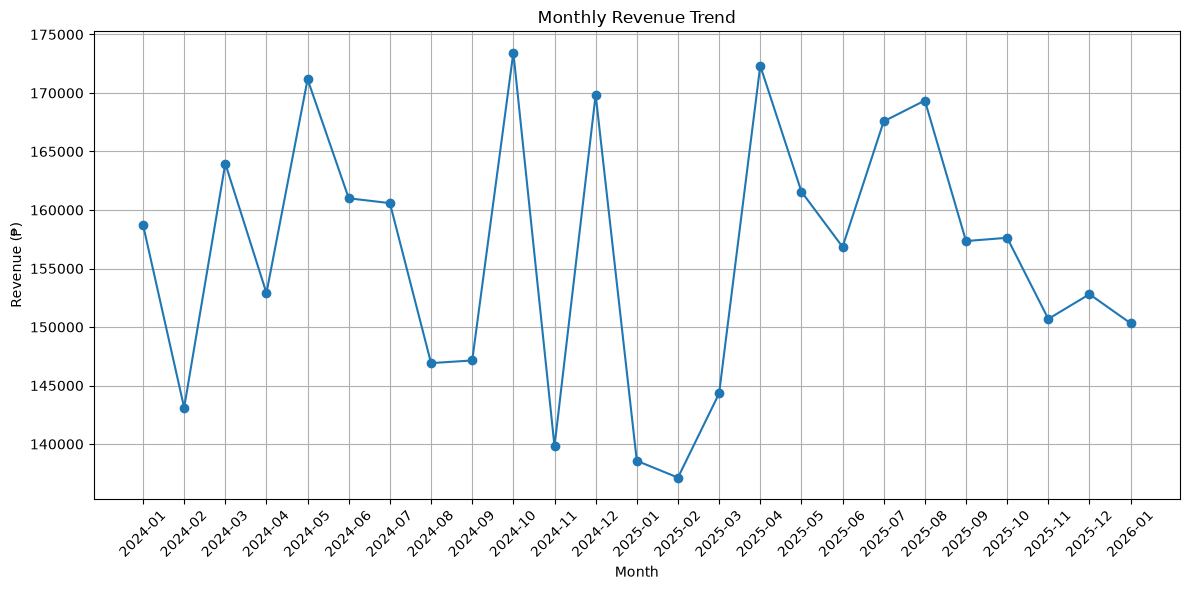

In [89]:
#Visualize the monthly revenue

import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))

plt.plot(
    monthly_revenue['month'],
    monthly_revenue['net_revenue'],
    marker='o'
)

plt.title('Monthly Revenue Trend')
plt.xlabel('Month')
plt.ylabel('Revenue (₱)')
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()


In [90]:
#Create Top 10 Products by Revenue

top_products = (
    sales_data.groupby('product_name')['net_revenue']
    .sum()
    .sort_values(ascending=False)
    .head(10)
    .reset_index()
)

top_products

,product_name,net_revenue
0,KidJoy Toys 607,25315.71269
1,GlowCo Fashion 931,21929.76665
2,FreshCart Fashion 562,21090.48561
3,FitPro Home 691,20948.87239
4,KidJoy Beauty 543,20308.11712
5,GlowCo Beauty 566,19936.89858
6,HomeEase Sports 288,19012.97855
7,HomeEase Groceries 174,17938.34996
8,UrbanWear Groceries 328,17759.08344
9,BookNest Groceries 219,16644.36904


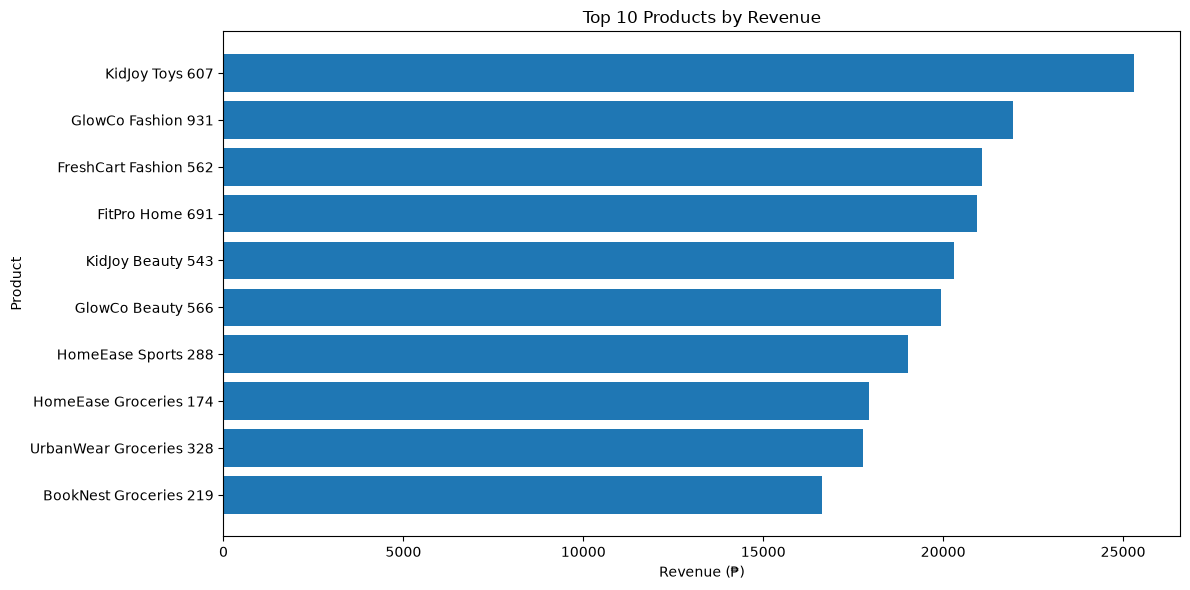

In [91]:
#Visualize Top 10 Products by Revenue

plt.figure(figsize=(12, 6))

plt.barh(
    top_products['product_name'],
    top_products['net_revenue']
)

plt.title('Top 10 Products by Revenue')
plt.xlabel('Revenue (₱)')
plt.ylabel('Product')
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

In [92]:
#Creating revenue by category

category_revenue = (
    sales_data.groupby('category')['net_revenue']
    .sum()
    .sort_values(ascending=False)
    .reset_index()
)

category_revenue

,category,net_revenue
0,Toys,693160.88113
1,Electronics,680785.48369
2,Fashion,648649.91984
3,Beauty,644429.02702
4,Home & Kitchen,638998.48193
5,Books,582538.00048
6,Groceries,571960.88768
7,Sports,540243.07122


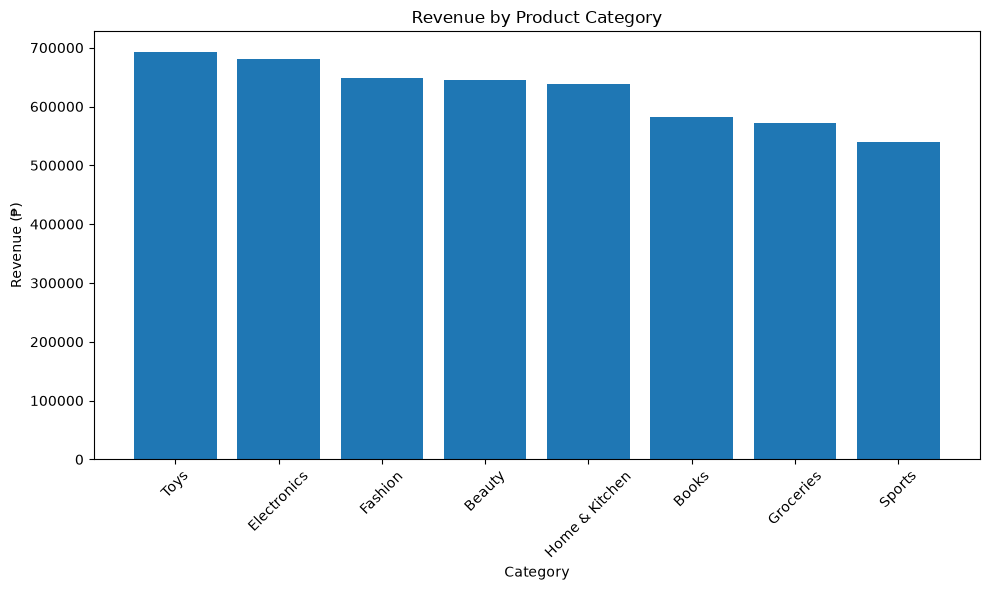

In [93]:
#Visualize revenue by category

plt.figure(figsize=(10, 6))

plt.bar(
    category_revenue['category'],
    category_revenue['net_revenue']
)

plt.title('Revenue by Product Category')
plt.xlabel('Category')
plt.ylabel('Revenue (₱)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [94]:
#Creating Revenue by Region and City

region_revenue = (
    sales_data.groupby('region_name')['net_revenue']
    .sum()
    .sort_values(ascending=False)
    .reset_index()
)

region_revenue

,region_name,net_revenue
0,Central Luzon,882055.45679
1,Central Visayas,859316.3873
2,Metro Manila,834130.9149
3,CARAGA,832959.71626
4,Northern Mindanao,824409.38577
5,CALABARZON,767893.89197


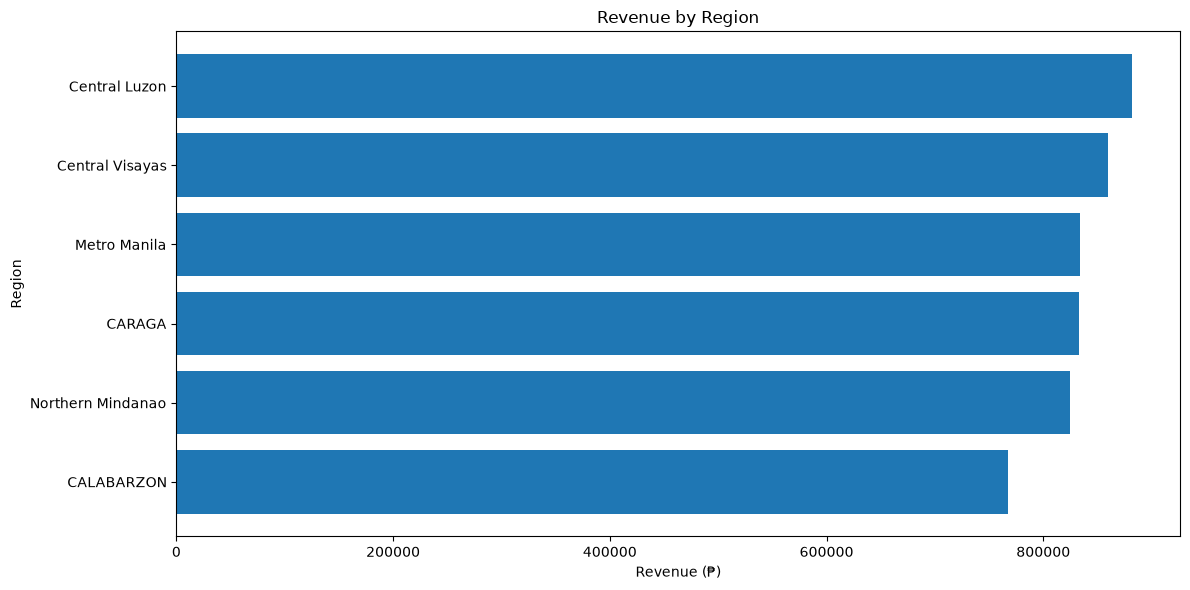

In [95]:
#Visualize Revenue by Region and City

plt.figure(figsize=(12, 6))

plt.barh(
    region_revenue['region_name'],
    region_revenue['net_revenue']
)

plt.title('Revenue by Region')
plt.xlabel('Revenue (₱)')
plt.ylabel('Region')
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

In [96]:
#Creating Revenue by City

city_revenue = (
    sales_data.groupby('city')['net_revenue']
    .sum()
    .sort_values(ascending=False)
    .head(10)
    .reset_index()
)

city_revenue

,city,net_revenue
0,Olongapo,323476.13377
1,Iligan,300708.97085
2,San Fernando,293473.69178
3,Angeles,265105.63124
4,Cagayan De Oro,264345.59076
5,Valencia,259354.82416
6,Tandag,246256.26973
7,Cebu City,231803.64534
8,Lapu-Lapu,221035.18458
9,Tagbilaran,203584.61747


In [97]:
#Creating Customer Spending Distribution

customer_spending = (
    sales_data.groupby('customer_id')['net_revenue']
    .sum()
    .reset_index()
)

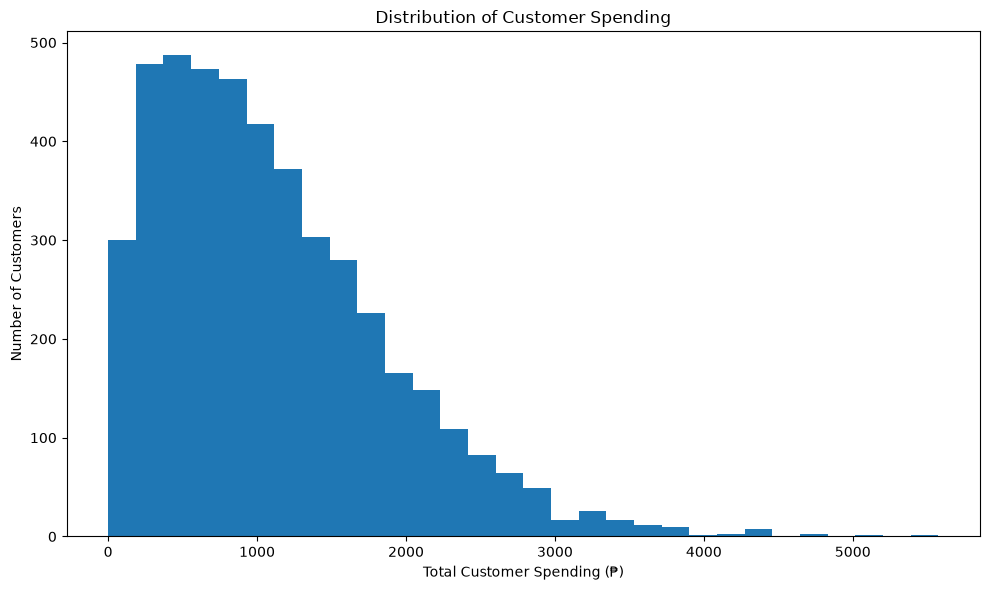

In [98]:
#Visualize Customer Spending Distribution

plt.figure(figsize=(10, 6))

plt.hist(
    customer_spending['net_revenue'],
    bins=30
)

plt.title('Distribution of Customer Spending')
plt.xlabel('Total Customer Spending (₱)')
plt.ylabel('Number of Customers')
plt.tight_layout()
plt.show()

In [99]:
#Creating New vs Repeat Customers

customer_orders = (
    sales_data.groupby('customer_id')['order_id']
    .nunique()
    .reset_index(name='total_orders')
)

In [100]:
#Classifying Customers

customer_orders['customer_type'] = np.where(
    customer_orders['total_orders'] == 1,
    'New Customer',
    'Repeat Customer'
)

In [101]:
#Count Customers

customer_type_summary = (
    customer_orders['customer_type']
    .value_counts()
    .reset_index()
)

customer_type_summary.columns = [
    'customer_type',
    'customer_count'
]

customer_type_summary

,customer_type,customer_count
0,Repeat Customer,3382
1,New Customer,1138


In [102]:
#Calculate Customers Percentage

customer_type_summary['percentage'] = (
    customer_type_summary['customer_count'] /
    customer_type_summary['customer_count'].sum()
) * 100

customer_type_summary

,customer_type,customer_count,percentage
0,Repeat Customer,3382,74.823009
1,New Customer,1138,25.176991


In [103]:
#Creating Returns and Cancellation Analysis

status_summary = (
    fact_table.groupby('order_status')['order_id']
    .nunique()
    .reset_index(name='total_orders')
)

status_summary

,order_status,total_orders
0,Cancelled,1229
1,Completed,9811
2,Pending,1524
3,Returned,576
4,Shipped,1806


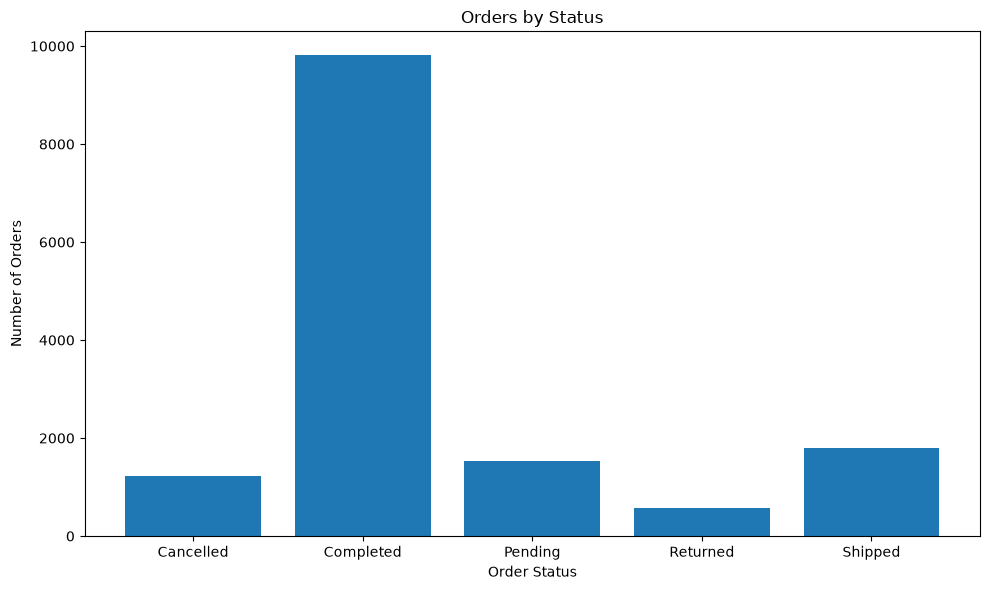

In [104]:
#Visualize Returns and Cancellation

plt.figure(figsize=(10, 6))

plt.bar(
    status_summary['order_status'],
    status_summary['total_orders']
)

plt.title('Orders by Status')
plt.xlabel('Order Status')
plt.ylabel('Number of Orders')
plt.tight_layout()
plt.show()

In [105]:
import os

os.makedirs("cleaned_data", exist_ok=True)

In [106]:
#Exporting cleaned dataset to csv

customers_clean.to_csv("cleaned_data/customers_cleaned.csv", index=False)

orders_clean.to_csv("cleaned_data/orders_cleaned.csv", index=False)

order_items_clean.to_csv("cleaned_data/order_items_cleaned.csv", index=False)

products_clean.to_csv("cleaned_data/products_cleaned.csv", index=False)

In [107]:
#Does it work

os.listdir("cleaned_data")

['customers_cleaned.csv',
 'orders_cleaned.csv',
 'order_items_cleaned.csv',
 'products_cleaned.csv']

In [108]:
duplicates = order_items_clean[
    order_items_clean.duplicated(
        subset=['order_item_id'],
        keep=False
    )
].sort_values('order_item_id')

duplicates.head(20)

,order_item_id,order_id,product_id,quantity,unit_price_at_purchase
944,ITEM000000945,ORD0000372,PROD00064,2,90.72
37526,ITEM000000945,ORD0000372,PROD00064,2,90.72
1163,ITEM000001164,ORD0000458,PROD00166,1,85.65
37692,ITEM000001164,ORD0000458,PROD00166,1,85.65
1272,ITEM000001273,ORD0000503,PROD00536,2,91.52
37695,ITEM000001273,ORD0000503,PROD00536,2,91.52
1311,ITEM000001312,ORD0000520,PROD00077,4,135.59
37543,ITEM000001312,ORD0000520,PROD00077,4,135.59
1353,ITEM000001354,ORD0000534,PROD00505,2,100.11
37550,ITEM000001354,ORD0000534,PROD00505,2,100.11


In [109]:
order_items_clean = order_items_clean.drop_duplicates().copy()

In [110]:
order_items_clean.duplicated(
    subset=['order_item_id']
).sum()

np.int64(0)

In [111]:
conflicting_ids = order_items_clean[
    order_items_clean.duplicated(
        subset=['order_item_id'],
        keep=False
    )
].sort_values('order_item_id')

conflicting_ids

,order_item_id,order_id,product_id,quantity,unit_price_at_purchase


In [112]:
order_items_clean.to_csv(
    "cleaned_data/order_items_cleaned.csv",
    index=False
)

In [117]:
order_items_clean = order_items_clean.drop_duplicates().copy()